In [2]:
import pandas as pd
import numpy as np
import sys
import os
sys.path.append(os.path.abspath(".."))
import matplotlib.pyplot as plt
from src.returns import prices_wide, log_returns
from src.build_dataset import build_dataset
import seaborn as sns 

In [3]:
def generate_scatter_plot(df: pd.DataFrame, x_col: str = "PKO BP", y_col: str = "Pekao") -> plt.Axes:
    """Scatter of daily returns of two banks; one point per day where both have a return."""
    data = df[[x_col, y_col]].dropna()

    ax = data.plot.scatter(
        x=x_col,
        y=y_col,
        s=10,
        alpha=0.3,
        color="royalblue",
        title=f"Daily log returns: {x_col} vs {y_col}",
    )
    ax.set_xlabel(f"Log return {x_col}")
    ax.set_ylabel(f"Log return {y_col}")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.grid(True, linestyle="--", alpha=0.5)
    return ax

In [4]:
def calculate_joint_probability(df: pd.DataFrame,first_bank: str = "PKO BP", second_bank: str = "Pekao", val: float = -0.02) -> float:
    """ Calculating probability both banks will lose more than 2% per one day. """
    df_ = df.copy()
    df_ = df_[[first_bank,second_bank]].dropna()
    total_length = len(df_)
    losses_greater_than_2_pr = len( df_[ (df_[first_bank]<=val) & (df_[second_bank]<=val) ])
    return losses_greater_than_2_pr/total_length

In [5]:
def calculate_indenpendence_probability(df: pd.DataFrame, p_joint: float,
                                        first_bank: str = "PKO BP", second_bank: str = "Pekao", 
                                        val: float = -0.02) -> dict:
    """ Calculating independence probability. """
    df_ = df.copy()
    df_ = df_[[first_bank,second_bank]].dropna()
    
    df_["flag_first_bank_losses"] = np.where(df_[first_bank]<=val,1,0)
    df_["flag_second_bank_losses"] = np.where(df_[second_bank]<=val,1,0)
    df_["both_banks_losses"] = np.where(((df_[first_bank]<=val) & (df_[second_bank]<=val)),1,0)

    total_len = len(df_)
    first_bank_losses_prob = sum(df_["flag_first_bank_losses"])/total_len
    second_bank_losses_prob = sum(df_["flag_second_bank_losses"])/total_len
    both_bank_losses = first_bank_losses_prob * second_bank_losses_prob

    return {
        "p_pko":first_bank_losses_prob,
        "p_peo":second_bank_losses_prob,
        "p_indep":both_bank_losses,
        "ratio":p_joint/both_bank_losses
    }

In [6]:
def conditional_probability(df: pd.DataFrame, first_bank_losses_prob: float, second_bank_losses_prob: float,both_bank_losses: float) -> float:
    first_bank_loss_if_second_lose = both_bank_losses / second_bank_losses_prob
    second_bank_loss_if_first_lose = both_bank_losses / first_bank_losses_prob
    
    return first_bank_loss_if_second_lose,second_bank_loss_if_first_lose
    

    

In [208]:
def correlation_matrix(df: pd.DataFrame) -> pd.DataFrame:
    """Pearson correlation of columns, computed on days where every column has a value."""
    return df.dropna().corr()


def plot_correlation_heatmap(corr: pd.DataFrame, title: str = "Correlation of daily log returns") -> plt.Axes:
    """Heatmap of a correlation matrix with values in cells, colour scale from -1 to 1."""
    ax = sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="RdBu_r", square=True)
    ax.set_title(title)
    return ax


def var_pattern(df: pd.DataFrame, wage: float) -> float:
    """Caclculating variance from log_returns. """
    wage_cols = []
    
    for c in df.columns:
        wage_col = df[c].sum() * wage
        wage_cols.append(wage_col)
    return sum(wage_cols) * wage


def var_port_var_data(df: pd.DataFrame) -> float:
    """Variance of an equal-weighted portfolio, computed from its daily deviations."""
    df = df.dropna()
    weight = 1 / len(df.columns)
    bank_means = df.mean()
    squared_devs = []

    for i in df.index:
        day_dev = 0
        for j in df.columns:
            day_dev += (df.loc[i, j] - bank_means[j]) * weight
        squared_devs.append(day_dev ** 2)

    return sum(squared_devs) / (len(df) - 1)


def var_div_effect(ret_full : pd.DataFrame, port_var_formula: float) -> dict[str, float]:
    avg_std = ret_full.std().mean()
    port_std = (port_var_formula) ** (1/2)
    
    return {
        "avg_std": avg_std,
        "port_std": port_std,
        "div_ratio": port_std / avg_std
    }
    

In [210]:
var_div_effect(ret_full, var_port_var_data(ret_full))

{'avg_std': 0.023071109628560783,
 'port_std': 0.018744082708604396,
 'div_ratio': 0.8124482528313349}

In [196]:
var_pattern(ret_full, (1/6))

0.20319607512691043

In [198]:
var_port_var_data(ret_full)

0.0003513406365870023

In [202]:
ret_full.std()

ticker
Alior         0.025443
ING           0.019650
Millennium    0.026764
PKO BP        0.020392
Pekao         0.020708
mBank         0.025470
dtype: float64

<Axes: title={'center': 'Correlation of daily log returns'}, xlabel='ticker', ylabel='ticker'>

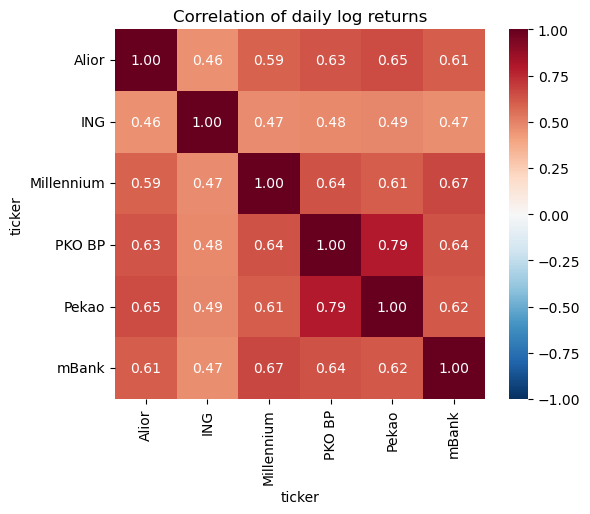

In [40]:
ret_full = log_ret.dropna()

corr = correlation_matrix(ret_full)
plot_correlation_heatmap(corr)

In [35]:
log_ret.corr()

ticker,Alior,ING,Millennium,PKO BP,Pekao,mBank
ticker,,,,,,
Alior,1.000000,0.454823,0.588162,0.623532,0.649409,0.605317
ING,0.454823,1.000000,0.471391,0.480735,0.488198,0.465600
Millennium,0.588162,0.471391,1.000000,0.636909,0.608968,0.668399
PKO BP,0.623532,0.480735,0.636909,1.000000,0.786875,0.640790
Pekao,0.649409,0.488198,0.608968,0.786875,1.000000,0.624288
mBank,0.605317,0.465600,0.668399,0.640790,0.624288,1.000000


In [20]:
stocks_df, fx_df = build_dataset()
x = prices_wide(stocks_df)
log_ret = log_returns(x)
log_ret.head(3)

ticker,Alior,ING,Millennium,PKO BP,Pekao,mBank
date,,,,,,
2015-01-02,-0.011998,-0.010419,-0.018238,-0.000839,-0.003363,0.000000
2015-01-05,-0.021249,-0.025234,-0.029890,-0.018644,-0.023865,-0.032863
2015-01-07,0.011468,0.007380,0.005044,0.003700,0.008589,0.027225


<Axes: title={'center': 'Daily log returns: PKO BP vs Pekao'}, xlabel='Log return PKO BP', ylabel='Log return Pekao'>

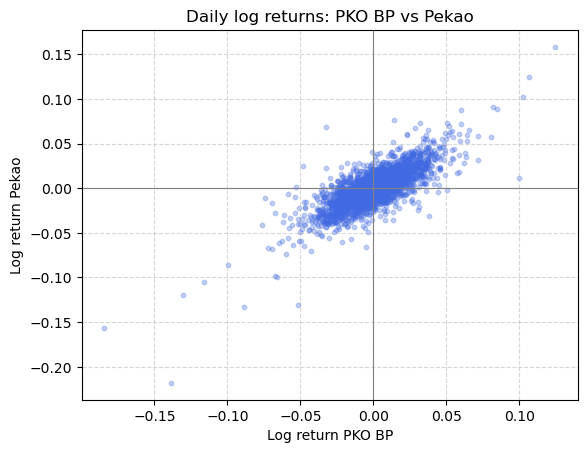

In [22]:
generate_scatter_plot(log_ret)

In [23]:
p_joint = calculate_joint_probability(log_ret)
p_joint

0.07224848075624578

In [24]:
ind_prob = calculate_indenpendence_probability(log_ret,p_joint)
ind_prob

{'p_pko': 0.12761647535449022,
 'p_peo': 0.1188386225523295,
 'p_indep': 0.015165766146110924,
 'ratio': 4.763918951418951}

In [25]:
ind_prob["p_pko"]

0.12761647535449022

In [26]:
p_pko_given_peo, p_cond = conditional_probability(
    log_ret, ind_prob["p_pko"], ind_prob["p_peo"], p_joint
)
p_pko_given_peo,p_cond

(0.6079545454545454, 0.566137566137566)